# OrbitalRoute AI — Notebook de base de datos

**Proyecto:** Sistema predictivo de QoS y enrutamiento adaptativo en redes satelitales LEO.

Este notebook sigue la arquitectura descrita en el documento integrador:
- Fuente original: CelesTrak / NORAD, conjuntos GP/TLE.
- Constelaciones contempladas: Starlink, OneWeb e Iridium NEXT.
- Tablas internas: `satellites`, `orbital_data`, `links` y `qos_metrics`.
- Campos calculados: posiciones, conectividad y métricas derivadas.

**Distinción importante:** los elementos orbitales descargados de CelesTrak son datos de origen. Las posiciones se calculan al propagar los elementos orbitales. Los enlaces y métricas QoS se generan en el procesamiento o la simulación; no se deben presentar como campos originales de CelesTrak. Este notebook no inventa mediciones reales de latencia ni disponibilidad.


## 1. Instalar las librerías

Ejecuta esta celda dentro del notebook. `%pip` instala en el mismo kernel que ejecuta Jupyter.

In [1]:
%pip install pandas numpy matplotlib requests sgp4 networkx sqlalchemy

Note: you may need to restart the kernel to use updated packages.


## 2. Importar librerías y configurar el proyecto

In [2]:
import io
import sqlite3
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from datetime import datetime, timezone
from sgp4.api import Satrec, jday
from sqlalchemy import create_engine

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print("Librerías cargadas correctamente")


Librerías cargadas correctamente


## 3. Descargar datos orbitales originales de CelesTrak

Se consultan las constelaciones Starlink, OneWeb e Iridium NEXT mediante el servicio público GP de CelesTrak en formato CSV. La descarga se realiza al ejecutar el notebook, por lo que los registros pueden cambiar con las actualizaciones de la fuente.

Si CelesTrak modifica los nombres de grupo o el formato de respuesta, consulta su documentación oficial: https://celestrak.org/NORAD/elements/

In [3]:
CELESTRAK_URL = "https://celestrak.org/NORAD/elements/gp.php"

GROUPS = {
    "STARLINK": "starlink",
    "ONEWEB": "oneweb",
    "IRIDIUM-NEXT": "iridium-NEXT",
}

def download_group(group_name, constellation):
    params = {"GROUP": group_name, "FORMAT": "csv"}
    response = requests.get(CELESTRAK_URL, params=params, timeout=60)
    response.raise_for_status()
    data = pd.read_csv(io.StringIO(response.text))
    data["constellation"] = constellation
    data["source"] = "CelesTrak GP"
    return data

frames = []
for constellation, group_name in GROUPS.items():
    try:
        part = download_group(group_name, constellation)
        print(constellation, ":", len(part), "registros")
        frames.append(part)
    except Exception as exc:
        print("No fue posible descargar", constellation, "->", exc)

if not frames:
    raise RuntimeError(
        "No se pudo descargar ninguna constelación. Comprueba tu conexión y vuelve a ejecutar esta sección."
    )

tle_raw = pd.concat(frames, ignore_index=True)
display(tle_raw.head())
print("Total de registros:", len(tle_raw))


No fue posible descargar STARLINK -> 403 Client Error: Forbidden for url: https://celestrak.org/NORAD/elements/gp.php?GROUP=starlink&FORMAT=csv
ONEWEB : 651 registros
IRIDIUM-NEXT : 80 registros


,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,CLASSIFICATION_TYPE,NORAD_CAT_ID,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,constellation,source
0,ONEWEB-0012,2019-010A,2026-11-13T04:58:23.261088,13.165952,0.000124,87.9168,199.2307,60.5315,299.5939,0,U,44057,999,37117,0.000009,1.600000e-07,0,ONEWEB,CelesTrak GP
1,ONEWEB-0010,2019-010B,2026-11-13T05:34:51.100032,13.165939,0.000159,87.9181,199.2310,88.5338,271.5975,0,U,44058,999,37122,0.000055,3.400000e-07,0,ONEWEB,CelesTrak GP
2,ONEWEB-0008,2019-010C,2026-11-13T04:21:55.722816,13.165938,0.000185,87.9176,199.2360,68.5175,291.6152,0,U,44059,999,37133,0.000078,4.300000e-07,0,ONEWEB,CelesTrak GP
3,ONEWEB-0007,2019-010D,2026-11-13T06:13:23.573568,13.155485,0.000140,87.9068,229.5201,76.1140,284.0146,0,U,44060,999,37097,-0.000129,-3.600000e-07,0,ONEWEB,CelesTrak GP
4,ONEWEB-0006,2019-010E,2026-11-13T13:37:09.700032,13.155483,0.000178,87.9074,229.4389,78.1815,281.9516,0,U,44061,999,37106,-0.000194,-6.000000e-07,0,ONEWEB,CelesTrak GP


Total de registros: 731


## 4. Revisar, limpiar y normalizar los datos de origen

El catálogo GP/CSV puede incluir columnas como `OBJECT_NAME`, `OBJECT_ID`, `NORAD_CAT_ID`, `EPOCH`, `INCLINATION`, `ECCENTRICITY`, `RA_OF_ASC_NODE`, `ARG_OF_PERICENTER`, `MEAN_ANOMALY`, `MEAN_MOTION` y `BSTAR`. Se conservan las columnas disponibles en la descarga, ya que los campos pueden variar según el formato.

In [4]:
print("Columnas recibidas:")
print(tle_raw.columns.tolist())

tle_clean = tle_raw.copy()
if "NORAD_CAT_ID" in tle_clean.columns:
    tle_clean = tle_clean.dropna(subset=["NORAD_CAT_ID"])
    tle_clean["NORAD_CAT_ID"] = tle_clean["NORAD_CAT_ID"].astype(str).str.replace(r"\\.0$", "", regex=True)
    tle_clean = tle_clean.drop_duplicates(subset=["NORAD_CAT_ID"], keep="last")

print("Registros después de limpieza:", len(tle_clean))
print("Valores faltantes por columna:")
display(tle_clean.isna().sum().to_frame("missing"))
display(tle_clean.head())


Columnas recibidas:
['OBJECT_NAME', 'OBJECT_ID', 'EPOCH', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'ARG_OF_PERICENTER', 'MEAN_ANOMALY', 'EPHEMERIS_TYPE', 'CLASSIFICATION_TYPE', 'NORAD_CAT_ID', 'ELEMENT_SET_NO', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'constellation', 'source']
Registros después de limpieza: 731
Valores faltantes por columna:


,missing
OBJECT_NAME,0
OBJECT_ID,0
EPOCH,0
MEAN_MOTION,0
ECCENTRICITY,0
INCLINATION,0
RA_OF_ASC_NODE,0
ARG_OF_PERICENTER,0
MEAN_ANOMALY,0
EPHEMERIS_TYPE,0


,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,CLASSIFICATION_TYPE,NORAD_CAT_ID,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,constellation,source
0,ONEWEB-0012,2019-010A,2026-11-13T04:58:23.261088,13.165952,0.000124,87.9168,199.2307,60.5315,299.5939,0,U,44057,999,37117,0.000009,1.600000e-07,0,ONEWEB,CelesTrak GP
1,ONEWEB-0010,2019-010B,2026-11-13T05:34:51.100032,13.165939,0.000159,87.9181,199.2310,88.5338,271.5975,0,U,44058,999,37122,0.000055,3.400000e-07,0,ONEWEB,CelesTrak GP
2,ONEWEB-0008,2019-010C,2026-11-13T04:21:55.722816,13.165938,0.000185,87.9176,199.2360,68.5175,291.6152,0,U,44059,999,37133,0.000078,4.300000e-07,0,ONEWEB,CelesTrak GP
3,ONEWEB-0007,2019-010D,2026-11-13T06:13:23.573568,13.155485,0.000140,87.9068,229.5201,76.1140,284.0146,0,U,44060,999,37097,-0.000129,-3.600000e-07,0,ONEWEB,CelesTrak GP
4,ONEWEB-0006,2019-010E,2026-11-13T13:37:09.700032,13.155483,0.000178,87.9074,229.4389,78.1815,281.9516,0,U,44061,999,37106,-0.000194,-6.000000e-07,0,ONEWEB,CelesTrak GP


## 5. Crear la tabla `satellites`

Esta tabla almacena la identificación general de cada satélite. Corresponde a la entidad principal del modelo relacional del documento.

In [5]:
def first_existing_column(df, candidates):
    for col in candidates:
        if col in df.columns:
            return col
    return None

name_col = first_existing_column(tle_clean, ["OBJECT_NAME", "OBJECT_NAME".lower(), "name"])
norad_col = first_existing_column(tle_clean, ["NORAD_CAT_ID", "NORAD_CAT_ID".lower()])
object_col = first_existing_column(tle_clean, ["OBJECT_ID", "OBJECT_ID".lower()])
const_col = "constellation" if "constellation" in tle_clean.columns else None

satellites = pd.DataFrame()
satellites["satellite_id"] = tle_clean[norad_col].astype(str) if norad_col else tle_clean.index.astype(str)
satellites["norad_cat_id"] = tle_clean[norad_col].astype(str) if norad_col else None
satellites["object_name"] = tle_clean[name_col].astype(str) if name_col else "Sin nombre"
satellites["object_id"] = tle_clean[object_col].astype(str) if object_col else None
satellites["constellation"] = tle_clean[const_col] if const_col else "No especificada"
satellites = satellites.drop_duplicates("satellite_id").reset_index(drop=True)

display(satellites.head())
print("Satélites únicos:", len(satellites))


,satellite_id,norad_cat_id,object_name,object_id,constellation
0,44057,44057,ONEWEB-0012,2019-010A,ONEWEB
1,44058,44058,ONEWEB-0010,2019-010B,ONEWEB
2,44059,44059,ONEWEB-0008,2019-010C,ONEWEB
3,44060,44060,ONEWEB-0007,2019-010D,ONEWEB
4,44061,44061,ONEWEB-0006,2019-010E,ONEWEB


Satélites únicos: 731


## 6. Crear la tabla `orbital_data`

Se guardan los campos orbitales originales disponibles. Las posiciones X, Y y Z no se atribuyen al CSV original: se calculan mediante propagación SGP4 en la siguiente sección.

In [6]:
orbital_columns = [
    "EPOCH", "INCLINATION", "RA_OF_ASC_NODE", "ECCENTRICITY",
    "ARG_OF_PERICENTER", "MEAN_ANOMALY", "MEAN_MOTION",
    "BSTAR", "REV_AT_EPOCH"
]
available_orbital_columns = [c for c in orbital_columns if c in tle_clean.columns]

orbital_data = tle_clean[[norad_col] + available_orbital_columns].copy() if norad_col else tle_clean[available_orbital_columns].copy()
if norad_col:
    orbital_data = orbital_data.rename(columns={norad_col: "satellite_id"})
    orbital_data["satellite_id"] = orbital_data["satellite_id"].astype(str)
orbital_data["source"] = "CelesTrak GP"
orbital_data["downloaded_at_utc"] = datetime.now(timezone.utc).isoformat()

display(orbital_data.head())


,satellite_id,EPOCH,INCLINATION,RA_OF_ASC_NODE,ECCENTRICITY,ARG_OF_PERICENTER,MEAN_ANOMALY,MEAN_MOTION,BSTAR,REV_AT_EPOCH,source,downloaded_at_utc
0,44057,2026-11-13T04:58:23.261088,87.9168,199.2307,0.000124,60.5315,299.5939,13.165952,0.000009,37117,CelesTrak GP,2026-11-13T19:56:20.717529+00:00
1,44058,2026-11-13T05:34:51.100032,87.9181,199.2310,0.000159,88.5338,271.5975,13.165939,0.000055,37122,CelesTrak GP,2026-11-13T19:56:20.717529+00:00
2,44059,2026-11-13T04:21:55.722816,87.9176,199.2360,0.000185,68.5175,291.6152,13.165938,0.000078,37133,CelesTrak GP,2026-11-13T19:56:20.717529+00:00
3,44060,2026-11-13T06:13:23.573568,87.9068,229.5201,0.000140,76.1140,284.0146,13.155485,-0.000129,37097,CelesTrak GP,2026-11-13T19:56:20.717529+00:00
4,44061,2026-11-13T13:37:09.700032,87.9074,229.4389,0.000178,78.1815,281.9516,13.155483,-0.000194,37106,CelesTrak GP,2026-11-13T19:56:20.717529+00:00


## 7. Propagar órbitas y calcular posiciones (SGP4)

Para propagar correctamente se necesitan los elementos en formato TLE de dos líneas. El endpoint GP en CSV puede no incluir esas dos líneas; por eso esta sección obtiene también TLE para los identificadores NORAD disponibles y aplica SGP4. La posición resultante está expresada en el marco TEME y en kilómetros.

La época de cálculo se fija en UTC para que los resultados sean reproducibles. SGP4 produce posiciones calculadas, no posiciones almacenadas originalmente en el CSV.

In [7]:
MAX_SATELLITES_FOR_PROPAGATION = 150
norad_ids = satellites["norad_cat_id"].dropna().astype(str).head(MAX_SATELLITES_FOR_PROPAGATION).tolist()

tle_records = []
for norad_id in norad_ids:
    url = f"https://celestrak.org/NORAD/elements/gp.php?CATNR={norad_id}&FORMAT=tle"
    try:
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        lines = [line.strip() for line in r.text.splitlines() if line.strip()]
        line1 = next((x for x in lines if x.startswith("1 ")), None)
        line2 = next((x for x in lines if x.startswith("2 ")), None)
        name = next((x for x in lines if not x.startswith(("1 ", "2 "))), f"NORAD-{norad_id}")
        if line1 and line2:
            tle_records.append((norad_id, name, line1, line2))
    except Exception as exc:
        print("TLE no disponible para", norad_id, exc)

print("TLE válidos descargados:", len(tle_records))


TLE válidos descargados: 150


In [8]:
calculation_time = datetime.now(timezone.utc)
jd, fr = jday(
    calculation_time.year, calculation_time.month, calculation_time.day,
    calculation_time.hour, calculation_time.minute,
    calculation_time.second + calculation_time.microsecond / 1e6
)

positions = []
for norad_id, name, line1, line2 in tle_records:
    sat = Satrec.twoline2rv(line1, line2)
    error, r, v = sat.sgp4(jd, fr)
    if error == 0:
        positions.append({
            "satellite_id": str(norad_id),
            "timestamp_utc": calculation_time.isoformat(),
            "position_x_km": r[0], "position_y_km": r[1], "position_z_km": r[2],
            "velocity_x_km_s": v[0], "velocity_y_km_s": v[1], "velocity_z_km_s": v[2],
            "coordinate_frame": "TEME",
            "derived_by": "SGP4"
        })

positions_df = pd.DataFrame(positions)
display(positions_df.head())
print("Posiciones calculadas:", len(positions_df))


,satellite_id,timestamp_utc,position_x_km,position_y_km,position_z_km,velocity_x_km_s,velocity_y_km_s,velocity_z_km_s,coordinate_frame,derived_by
0,44057,2026-11-13T19:59:35.870347+00:00,-564.621681,-485.664286,7530.889042,6.835462,2.342396,0.662769,TEME,SGP4
1,44058,2026-11-13T19:59:35.870347+00:00,-5898.967205,-1875.499949,-4379.875429,-3.884233,-1.573293,5.912373,TEME,SGP4
2,44059,2026-11-13T19:59:35.870347+00:00,6465.395606,2362.181067,-3180.004490,-2.948127,-0.768338,-6.577272,TEME,SGP4
3,44060,2026-11-13T19:59:35.870347+00:00,4686.835774,5586.729654,-2087.395851,-1.488155,-1.345606,-6.965561,TEME,SGP4
4,44061,2026-11-13T19:59:35.870347+00:00,4940.439628,5741.475124,352.889294,0.024815,0.435019,-7.238667,TEME,SGP4


Posiciones calculadas: 150


## 8. Construir la tabla `links` a partir de una regla geométrica

La conectividad se deriva de las posiciones calculadas. Para este ejercicio se usa una distancia máxima ilustrativa de 2,000 km. Este umbral no representa por sí solo un modelo físico completo de enlaces ópticos ISL: para un análisis real deben añadirse línea de vista, restricciones de antena, capacidad y demás condiciones del enlace.

In [9]:
LINK_THRESHOLD_KM = 2000.0

links_rows = []
if len(positions_df) >= 2:
    pos = positions_df.reset_index(drop=True)
    for i in range(len(pos)):
        for j in range(i + 1, len(pos)):
            a, b = pos.iloc[i], pos.iloc[j]
            distance = float(np.linalg.norm(
                np.array([a.position_x_km, a.position_y_km, a.position_z_km]) -
                np.array([b.position_x_km, b.position_y_km, b.position_z_km])
            ))
            if distance <= LINK_THRESHOLD_KM:
                links_rows.append({
                    "link_id": f"{a.satellite_id}-{b.satellite_id}",
                    "link_source_id": a.satellite_id,
                    "link_destination_id": b.satellite_id,
                    "distance_km": distance,
                    "link_status": "candidate_by_distance",
                    "timestamp_utc": calculation_time.isoformat()
                })

links = pd.DataFrame(links_rows)
display(links.head())
print("Enlaces candidatos:", len(links))


,link_id,link_source_id,link_destination_id,distance_km,link_status,timestamp_utc
0,44057-45132,44057,45132,706.697761,candidate_by_distance,2026-11-13T19:59:35.870347+00:00
1,44057-45141,44057,45141,1435.893442,candidate_by_distance,2026-11-13T19:59:35.870347+00:00
2,44057-45163,44057,45163,1289.647958,candidate_by_distance,2026-11-13T19:59:35.870347+00:00
3,44057-45442,44057,45442,856.327777,candidate_by_distance,2026-11-13T19:59:35.870347+00:00
4,44057-47273,44057,47273,1136.399299,candidate_by_distance,2026-11-13T19:59:35.870347+00:00


Enlaces candidatos: 308


## 9. Construir la tabla `qos_metrics`

El documento define campos de latencia, pérdida y disponibilidad como métricas que se estiman o miden durante la simulación. CelesTrak no proporciona estas métricas. Por eso aquí se crea la estructura vacía para almacenar resultados futuros, sin inventar mediciones.

In [10]:
qos_metrics = pd.DataFrame(columns=[
    "metric_id", "link_id", "timestamp_utc",
    "latency_ms", "packet_loss_rate", "availability_rate",
    "algorithm_used", "measurement_type"
])
print("Estructura QoS:")
display(qos_metrics)
print("Nota: se completará con mediciones reales o resultados identificados de una simulación.")


Estructura QoS:


,metric_id,link_id,timestamp_utc,latency_ms,packet_loss_rate,availability_rate,algorithm_used,measurement_type


Nota: se completará con mediciones reales o resultados identificados de una simulación.


## 10. Visualización exploratoria de posiciones

La gráfica representa las posiciones calculadas por SGP4 en el plano X-Y del marco TEME. Es una proyección 2D de posiciones 3D.

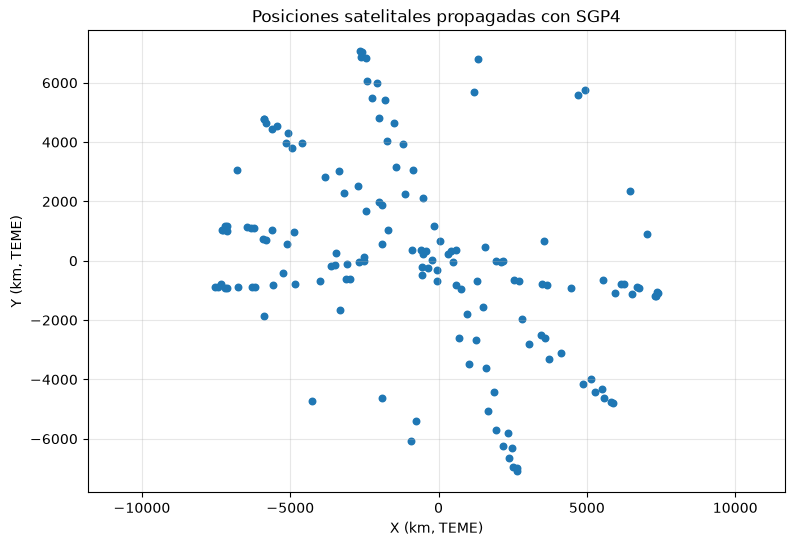

In [11]:
if not positions_df.empty:
    plt.figure(figsize=(9, 6))
    plt.scatter(positions_df["position_x_km"], positions_df["position_y_km"], s=22)
    plt.xlabel("X (km, TEME)")
    plt.ylabel("Y (km, TEME)")
    plt.title("Posiciones satelitales propagadas con SGP4")
    plt.grid(True, alpha=0.3)
    plt.axis("equal")
    plt.show()
else:
    print("No hay posiciones disponibles para graficar.")


## 11. Crear el grafo y calcular conectividad

Los nodos representan satélites y las aristas representan enlaces candidatos según el umbral geométrico aplicado. Este grafo es una derivación de los datos orbitales, no una tabla original de CelesTrak.

Nodos: 150
Enlaces candidatos: 308
Componentes conexas: 24


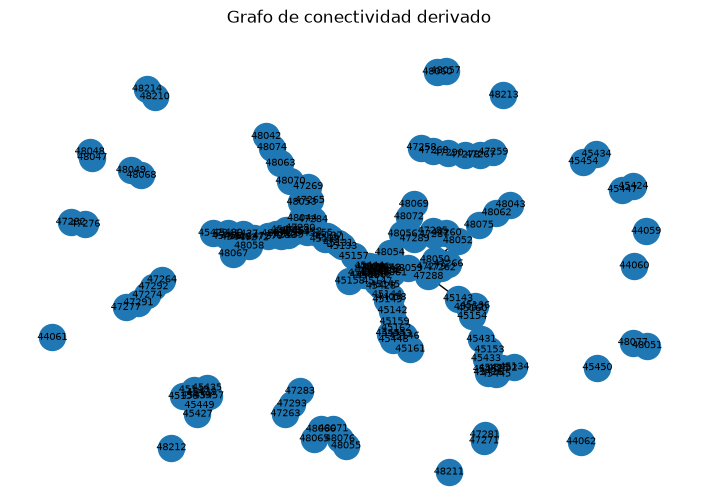

In [12]:
G = nx.Graph()
for sid in positions_df["satellite_id"].astype(str).tolist():
    G.add_node(sid)

for _, row in links.iterrows():
    G.add_edge(
        str(row["link_source_id"]),
        str(row["link_destination_id"]),
        distance_km=float(row["distance_km"])
    )

print("Nodos:", G.number_of_nodes())
print("Enlaces candidatos:", G.number_of_edges())
print("Componentes conexas:", nx.number_connected_components(G) if G.number_of_nodes() else 0)

if G.number_of_nodes() > 0:
    plt.figure(figsize=(9, 6))
    graph_pos = nx.spring_layout(G, seed=17)
    nx.draw_networkx(G, graph_pos, node_size=350, font_size=7, with_labels=True)
    plt.title("Grafo de conectividad derivado")
    plt.axis("off")
    plt.show()


## 12. Guardar las cuatro tablas en SQLite y exportar CSV

Se crea una base local `orbitalroute.db` para demostrar el modelo relacional. También se exportan CSV para revisión y entrega. SQLite se usa como alternativa ligera para el notebook; el documento plantea PostgreSQL + PostGIS + TimescaleDB para la arquitectura de destino.

In [13]:
tables = {
    "satellites": satellites,
    "orbital_data": orbital_data,
    "links": links,
    "qos_metrics": qos_metrics
}

db_path = "orbitalroute.db"
with sqlite3.connect(db_path) as conn:
    for table_name, table_df in tables.items():
        table_df.to_sql(table_name, conn, if_exists="replace", index=False)

for table_name, table_df in tables.items():
    table_df.to_csv(f"{table_name}.csv", index=False)

print("Base de datos guardada:", db_path)
print("CSV exportados:", ", ".join(f"{name}.csv" for name in tables))


Base de datos guardada: orbitalroute.db
CSV exportados: satellites.csv, orbital_data.csv, links.csv, qos_metrics.csv


## 13. Consultar la base de datos con SQL

In [14]:
with sqlite3.connect("orbitalroute.db") as conn:
    resumen = pd.read_sql_query(
        "SELECT constellation, COUNT(*) AS total_satellites "
        "FROM satellites GROUP BY constellation",
        conn
    )
display(resumen)

with sqlite3.connect("orbitalroute.db") as conn:
    print(pd.read_sql_query("SELECT * FROM orbital_data LIMIT 5", conn))


,constellation,total_satellites
0,IRIDIUM-NEXT,80
1,ONEWEB,651


  satellite_id                       EPOCH  INCLINATION  RA_OF_ASC_NODE  ECCENTRICITY  ARG_OF_PERICENTER  MEAN_ANOMALY  MEAN_MOTION  \
0        44057  2026-11-13T04:58:23.261088      87.9168        199.2307      0.000124            60.5315      299.5939    13.165952   
1        44058  2026-11-13T05:34:51.100032      87.9181        199.2310      0.000159            88.5338      271.5975    13.165939   
2        44059  2026-11-13T04:21:55.722816      87.9176        199.2360      0.000185            68.5175      291.6152    13.165938   
3        44060  2026-11-13T06:13:23.573568      87.9068        229.5201      0.000140            76.1140      284.0146    13.155485   
4        44061  2026-11-13T13:37:09.700032      87.9074        229.4389      0.000178            78.1815      281.9516    13.155483   

      BSTAR  REV_AT_EPOCH        source                 downloaded_at_utc  
0  0.000009         37117  CelesTrak GP  2026-11-13T19:56:20.717529+00:00  
1  0.000055         37122  CelesTrak 

## 14. Diccionario de datos y conclusión

| Tabla | Contenido |
|---|---|
| `satellites` | Identificación, nombre, NORAD y constelación |
| `orbital_data` | Parámetros orbitales de CelesTrak y fecha de descarga |
| `links` | Enlaces candidatos derivados de las posiciones |
| `qos_metrics` | Estructura para métricas de latencia, pérdida y disponibilidad |

**Conclusión:** el notebook implementa una primera versión reproducible del flujo descrito en el proyecto: ingesta de datos orbitales, limpieza, propagación SGP4, cálculo de posiciones, derivación de enlaces y almacenamiento relacional. Las métricas QoS permanecen vacías hasta que se incorporen mediciones o resultados de simulación identificados. El almacenamiento local SQLite es didáctico; la arquitectura propuesta en el documento contempla PostgreSQL, PostGIS y TimescaleDB.

**Fuentes del proyecto:** CelesTrak GP data (https://celestrak.org/NORAD/elements/), SGP4 Python package (https://pypi.org/project/sgp4/), NetworkX (https://networkx.org/documentation/stable/).
